Ali Hisham AlJamed 2240005868 7MA1 / MA01

# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [3]:
df = pd.read_csv("Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [4]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [5]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [6]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

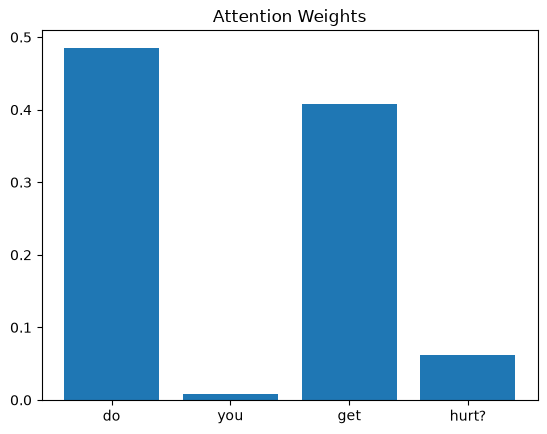

In [7]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

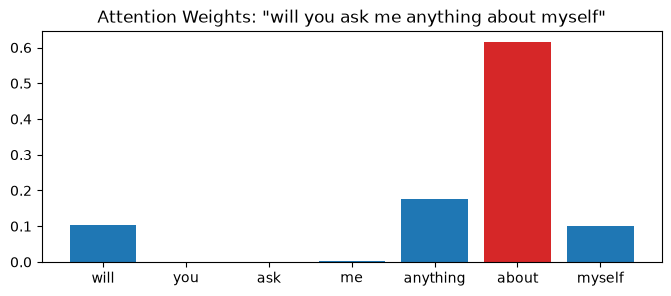

Question: will you ask me anything about myself
Highest attention: "about" (0.616)
True answer group: 2 | Predicted: 2



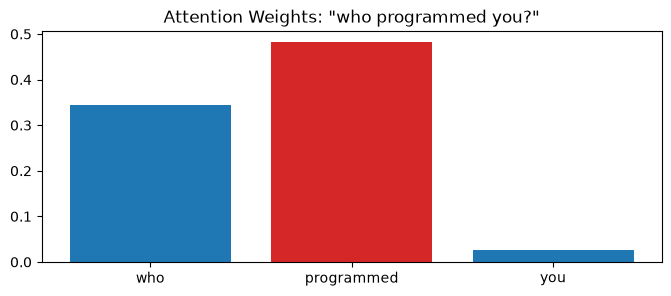

Question: who programmed you?
Highest attention: "programmed" (0.483)
True answer group: 3 | Predicted: 3



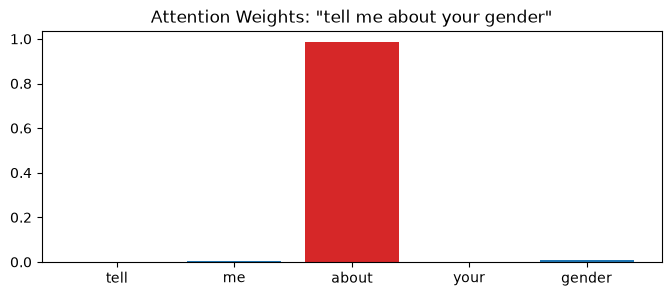

Question: tell me about your gender
Highest attention: "about" (0.986)
True answer group: 4 | Predicted: 2



In [8]:
from tensorflow.keras.preprocessing.text import text_to_word_sequence

# Three questions from three different answer groups
# (the first rows of the dataset are all answer_id 0, so don't just take the first three)
sample = df.groupby("answer_id").head(1).sample(3, random_state=1)

for i in sample.index:
    question = df["question"][i]
    words = text_to_word_sequence(question)   # same lowercasing/punctuation removal as Step 3

    with torch.no_grad():
        prediction, weights = model(X[i:i+1])

    w = weights[0, :len(words)].tolist()
    top = max(range(len(words)), key=lambda k: w[k])
    colors = ["tab:red" if k == top else "tab:blue" for k in range(len(words))]

    plt.figure(figsize=(8, 3))
    plt.bar(words, w, color=colors)
    plt.title(f'Attention Weights: "{question}"')
    plt.show()

    print(f'Question: {question}')
    print(f'Highest attention: "{words[top]}" ({w[top]:.3f})')
    print(f'True answer group: {y[i].item()} | Predicted: {prediction.argmax(1).item()}\n')

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

"can you throw up?"
  Highest attention: "up" (0.353)
  True group: 0 | Predicted: 3

"do you ever get hurt?"
  Highest attention: "do" (0.430)
  True group: 0 | Predicted: 0



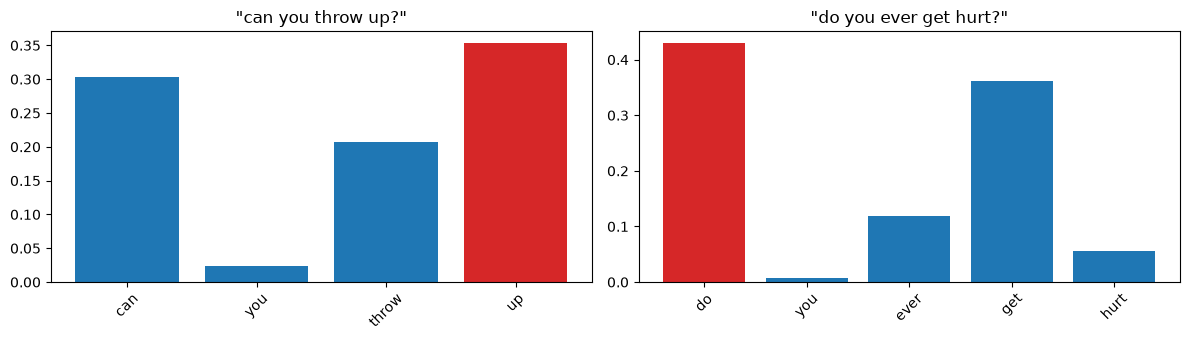

In [9]:
from itertools import combinations
from tensorflow.keras.preprocessing.text import text_to_word_sequence

group = 0   # change this to try another answer group
idx = df.index[df["answer_id"] == group].tolist()

def overlap(a, b):
    wa = set(text_to_word_sequence(df["question"][a]))
    wb = set(text_to_word_sequence(df["question"][b]))
    return len(wa & wb) / len(wa | wb)

# Same meaning (same answer group), most different wording
i, j = min(combinations(idx, 2), key=lambda p: overlap(*p))
# Or choose your own pair instead, e.g.: i, j = 1, 4

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, k in zip(axes, (i, j)):
    question = df["question"][k]
    words = text_to_word_sequence(question)

    with torch.no_grad():
        prediction, weights = model(X[k:k+1])

    w = weights[0, :len(words)].tolist()
    top = max(range(len(words)), key=lambda m: w[m])
    colors = ["tab:red" if m == top else "tab:blue" for m in range(len(words))]

    ax.bar(words, w, color=colors)
    ax.set_title(f'"{question}"')
    ax.tick_params(axis="x", rotation=45)

    print(f'"{question}"')
    print(f'  Highest attention: "{words[top]}" ({w[top]:.3f})')
    print(f'  True group: {y[k].item()} | Predicted: {prediction.argmax(1).item()}\n')

plt.tight_layout()
plt.show()